# CCE3206 - Digital Signal Processing
## Practical 1: The sampling theorem

## Task 1

In [29]:
import numpy as np

# simulate for 0.1 s, with 1000 samples
duration = 0.1
N = 1000
# t is a list of 1000 time samples in [0, 0.1)
t = np.linspace(0, duration, N, endpoint=False)

# x is the signal x(t) = sin(2πFt)
x = np.sin(2 * np.pi * 100 * t)

# period of pulse train
train_period = 10
# width of single pulse
pulse_width = 1
# p is a periodic pulse train
p = np.arange(N) % train_period < pulse_width

# y is the sampled sinusoid
y = x * p

## Task 2

In [30]:
from scipy.fft import fft, fftfreq

# F is the list of frequencies for the DFT
F = fftfreq(N, duration / N)

# X(F) is the DFT of x(t)
X = fft(x) / N
# the power spectrum of X(F) is |X(F)|²
Xp = np.abs(X) ** 2

# Repeat for P(F) and Y(F):
P = fft(p) / N 
Pp = np.abs(P) ** 2 

Y = fft(y) / N
Yp = np.abs(Y) ** 2



## Task 3

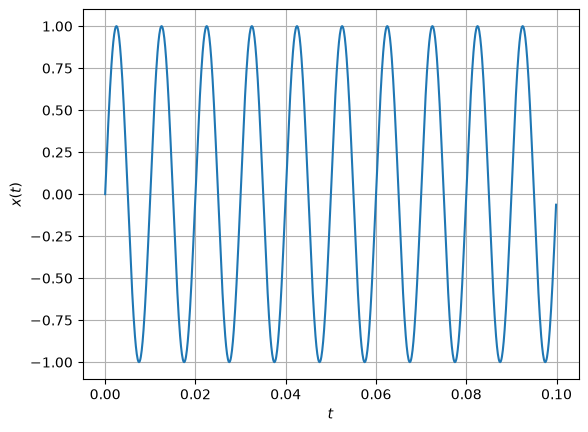

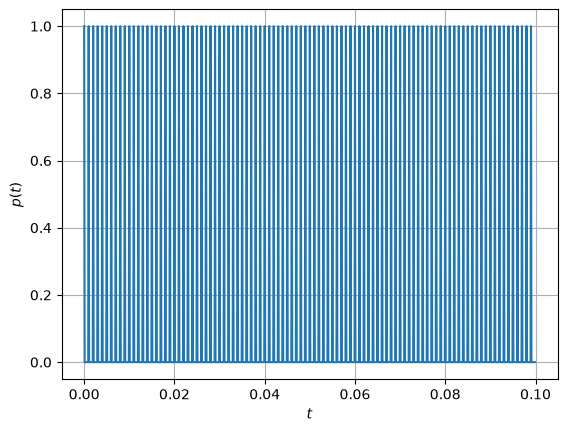

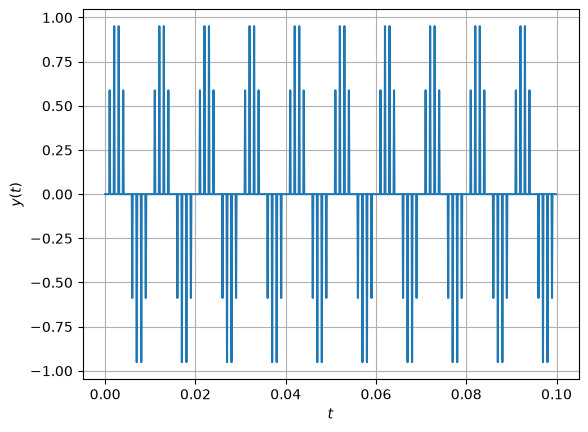

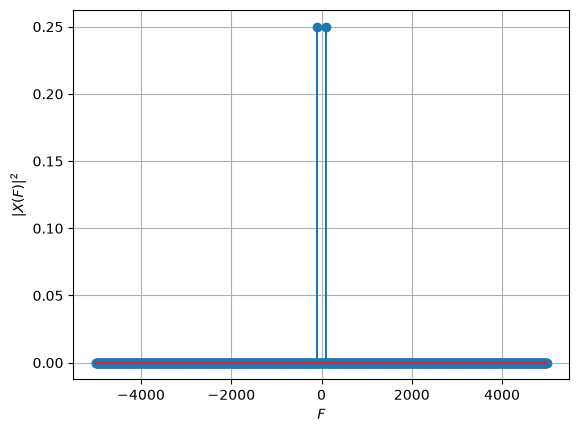

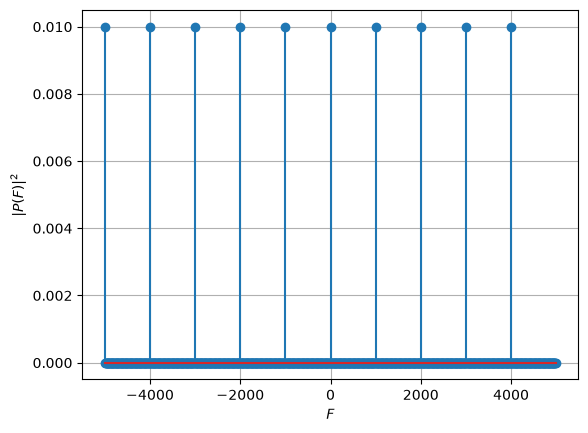

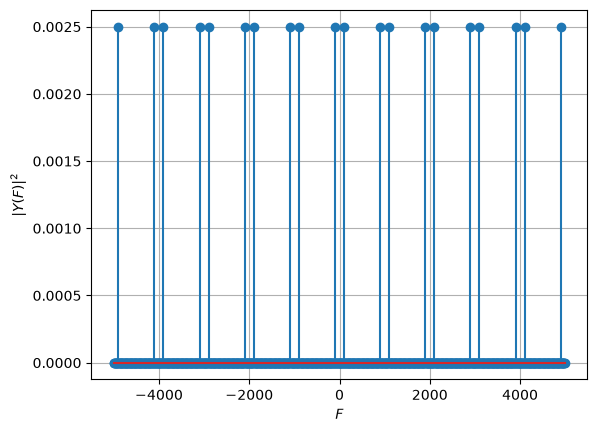

In [31]:
import matplotlib.pyplot as plt

# Plot x(t) against t
fig, ax = plt.subplots()
ax.plot(t, x)
ax.set_xlabel('$t$')
ax.set_ylabel('$x(t)$')
ax.grid(True)

# Repeat for p(t) and y(t)
fig, ax = plt.subplots()
ax.plot(t, p)
ax.set_xlabel('$t$')
ax.set_ylabel('$p(t)$')
ax.grid(True)

fig, ax = plt.subplots()
ax.plot(t, y)
ax.set_xlabel('$t$')
ax.set_ylabel('$y(t)$')
ax.grid(True)

# Plot |X(F)|^2 against F
fig, ax = plt.subplots()
ax.stem(F, Xp)
ax.set_xlabel('$F$')
ax.set_ylabel('$|X(F)|^2$')
ax.grid(True)

# Repeat for |P(F)|^2 and |Y(F)|^2
fig, ax = plt.subplots()
ax.stem(F, Pp)
ax.set_xlabel('$F$')
ax.set_ylabel('$|P(F)|^2$')
ax.grid(True)

fig, ax = plt.subplots()
ax.stem(F, Yp)
ax.set_xlabel('$F$')
ax.set_ylabel('$|Y(F)|^2$')
ax.grid(True)

plt.show()

## Task 4

From the values set for the pulse train: 
- The simulation sampling frequency is $F_{\text{sim}} = 1000/0.1 = 10{,}000$ Hz, (or 10kHz)

- The pulse train has a period of 10 simulation samples.

Therefore, the effective sampling frequency is:

$$
F_s = \frac{10000}{10} = 1000 \text{ Hz}
$$

This can be confirmed from the plot of $y(t)$ against $t$ by checking that consecutive sampling instants are present at a rate of 1000 Hz: 


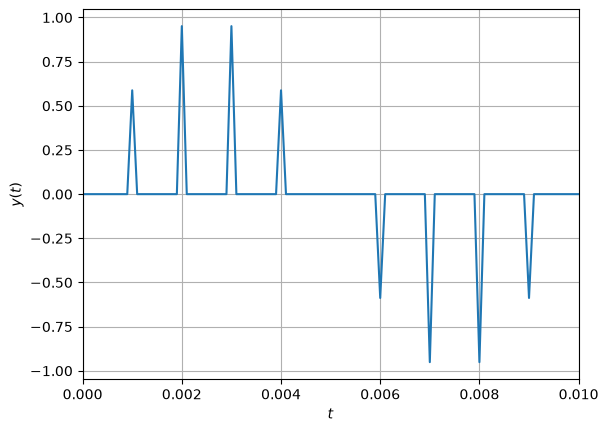

In [32]:
fig, ax = plt.subplots()
ax.plot(t, y)
ax.set_xlabel('$t$')
ax.set_ylabel('$y(t)$')
ax.grid(True)
ax.set_xlim([0, 0.01])
plt.show()

In the interval $0 \leq t < 0.01$ s, there are 10 sampling instants, spaced 0.001 s apart. Only eight spikes are visible because the samples at $t = 0$ s and $t = 0.005$ s have zero amplitude, where the sine wave crosses zero.

Since there are 10 samples in 0.01 seconds, the sampling frequency is $10 / 0.01 = 1000$ samples per second, confirming the calculated value of 1000 Hz.

## Task 5

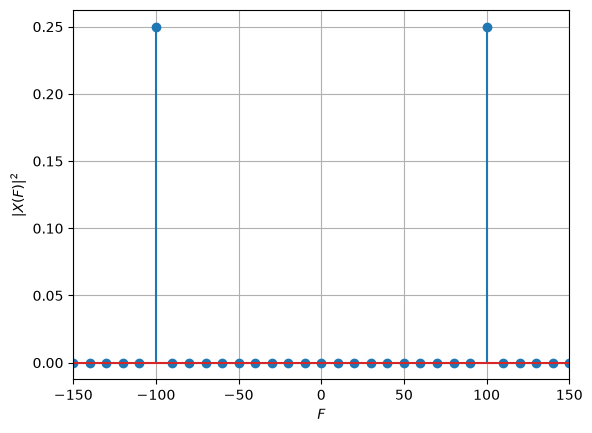

Frequency: 100.0 Hz
Power: 0.0025
Frequency: 900.0 Hz
Power: 0.0025
Frequency: 1100.0 Hz
Power: 0.0025
Frequency: 1900.0 Hz
Power: 0.0025
Frequency: 2100.0 Hz
Power: 0.0025
Frequency: 2900.0 Hz
Power: 0.0025
Frequency: 3100.0 Hz
Power: 0.0025
Frequency: 3900.0 Hz
Power: 0.0025
Frequency: 4100.0 Hz
Power: 0.0025
Frequency: 4900.0 Hz
Power: 0.0025
Frequency: -4900.0 Hz
Power: 0.0025
Frequency: -4100.0 Hz
Power: 0.0025
Frequency: -3900.0 Hz
Power: 0.0025
Frequency: -3100.0 Hz
Power: 0.0025
Frequency: -2900.0 Hz
Power: 0.0025
Frequency: -2100.0 Hz
Power: 0.0025
Frequency: -1900.0 Hz
Power: 0.0025
Frequency: -1100.0 Hz
Power: 0.0025
Frequency: -900.0 Hz
Power: 0.0025
Frequency: -100.0 Hz
Power: 0.0025


In [33]:

fig, ax = plt.subplots()
ax.stem(F, Xp)
ax.set_xlabel('$F$')
ax.set_ylabel('$|X(F)|^2$')
ax.set_xlim([-150, 150])
ax.grid(True)
plt.show()

for i in range(N):
    if Yp[i] > 0.0001:
        print("Frequency:", F[i], "Hz")
        print(f"Power: {Yp[i]:.4f}")

As shown in the graph above, the power spectrum of the unsampled sine wave $x(t)$ has frequency components at $-100$ Hz and $+100$ Hz, each with power 0.25.

Since the range was quite large for the power spectrum of the sampled sine wave $y(t)$, I coded a simple for loop to print out the frequency components. These are printed above, however for clarity's sake, I repeated them below. 

The sampled sine wave $y(t)$ has frequency components at:

$\pm100$, $\pm900$, $\pm1100$, $\pm1900$, $\pm2100$, $\pm2900$, $\pm3100$, $\pm3900$, $\pm4100$ and $\pm4900$ Hz.

Each component has a plotted power of approximately 0.0025. To obtain the corrected power, we multiply by:

$$
\left(\frac{F_{\text{sim}}}{F_s}\right)^2
= \left(\frac{10000}{1000}\right)^2 = 100
$$

Therefore, the corrected power of each component is:

$$
0.0025 \times 100 = 0.25
$$

## Task 6

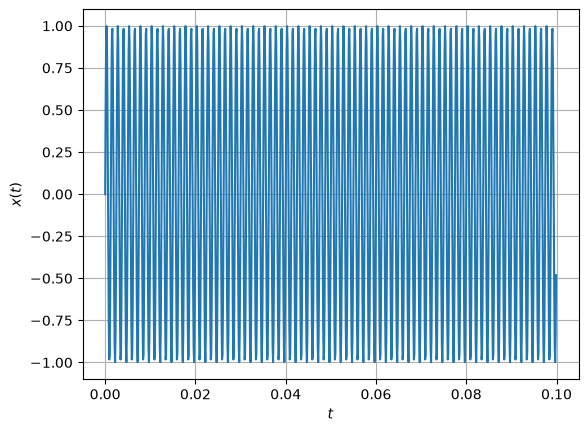

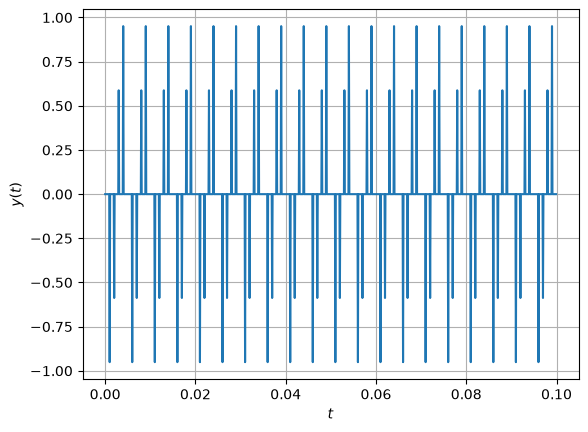

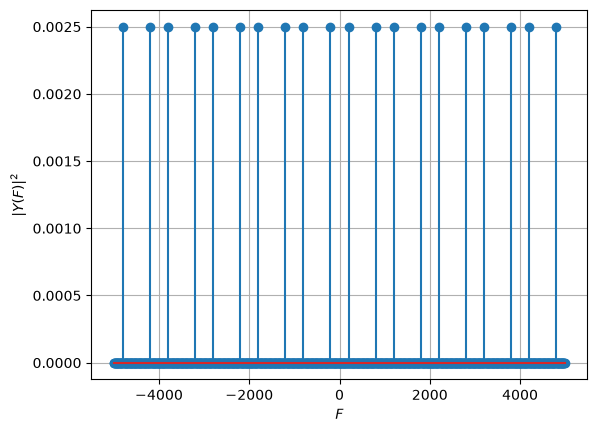

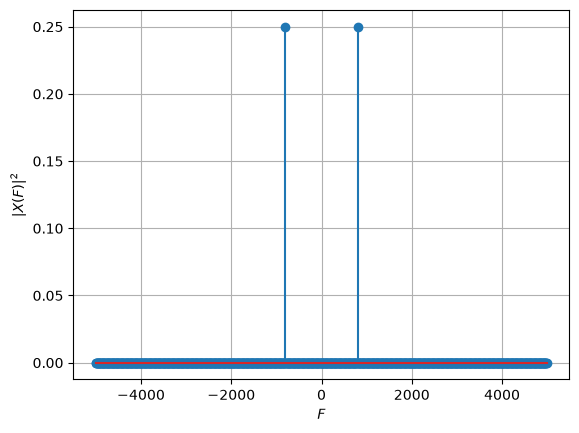

Frequency: 800.0 Hz
Power: 0.2500
Frequency: -800.0 Hz
Power: 0.2500
Frequency: 200.0 Hz
Power: 0.0025
Frequency: 800.0 Hz
Power: 0.0025
Frequency: 1200.0 Hz
Power: 0.0025
Frequency: 1800.0 Hz
Power: 0.0025
Frequency: 2200.0 Hz
Power: 0.0025
Frequency: 2800.0 Hz
Power: 0.0025
Frequency: 3200.0 Hz
Power: 0.0025
Frequency: 3800.0 Hz
Power: 0.0025
Frequency: 4200.0 Hz
Power: 0.0025
Frequency: 4800.0 Hz
Power: 0.0025
Frequency: -4800.0 Hz
Power: 0.0025
Frequency: -4200.0 Hz
Power: 0.0025
Frequency: -3800.0 Hz
Power: 0.0025
Frequency: -3200.0 Hz
Power: 0.0025
Frequency: -2800.0 Hz
Power: 0.0025
Frequency: -2200.0 Hz
Power: 0.0025
Frequency: -1800.0 Hz
Power: 0.0025
Frequency: -1200.0 Hz
Power: 0.0025
Frequency: -800.0 Hz
Power: 0.0025
Frequency: -200.0 Hz
Power: 0.0025


In [ ]:
# Change the sine wave to 800 Hz
x = np.sin(2 * np.pi * 800 * t)

# Sample the new sine wave
y = x * p

# Recalculate the power spectra
X = fft(x) / N
Xp = np.abs(X) ** 2

Y = fft(y) / N
Yp = np.abs(Y) ** 2


# Repeat task 5 :

# Time domain plots: 
fig, ax = plt.subplots()
ax.plot(t, x)
ax.set_xlabel('$t$')
ax.set_ylabel('$x(t)$')
ax.grid(True)
plt.show()

fig, ax = plt.subplots()
ax.plot(t, y)
ax.set_xlabel('$t$')
ax.set_ylabel('$y(t)$')
ax.grid(True)
plt.show()

# Power spectrum plots: 
fig, ax = plt.subplots()
ax.stem(F, Yp)
ax.set_xlabel('$F$')
ax.set_ylabel('$|Y(F)|^2$')
ax.grid(True)
plt.show()

fig, ax = plt.subplots()
ax.stem(F, Xp)
ax.set_xlabel('$F$')
ax.set_ylabel('$|X(F)|^2$')
ax.grid(True)
plt.show()

for i in range(N):
    if Xp[i] > 0.0001:
        print("Frequency:", F[i], "Hz")
        print(f"Power: {Xp[i]:.4f}")

print("==============")

for i in range(N):
    if Yp[i] > 0.0001:
        print("Frequency:", F[i], "Hz")
        print(f"Power: {Yp[i]:.4f}")


The unsampled sine wave $x(t)$ has frequency components at
$\pm800$ Hz, with power 0.25

The sampled sine wave $y(t)$ has frequency components at:

$\pm200$, $\pm800$, $\pm1200$, $\pm1800$, $\pm2200$, $\pm2800$, $\pm3200$, $\pm3800$, $\pm4200$ and $\pm4800$ Hz.

Each component has a plotted power of approximately 0.0025. To obtain the corrected power, we multiply by:

$$
\left(\frac{F_{\text{sim}}}{F_s}\right)^2
= \left(\frac{10000}{1000}\right)^2 = 100
$$

Therefore, the corrected power of each component is:

$$
0.0025 \times 100 = 0.25
$$

## Task 7

## Task 8

In [35]:
from scipy import signal 

# passband cut-off frequency
wp = 2 * np.pi * 500
# stopband edge frequency
ws = 2 * np.pi * 600
# maximum loss in passband (dB)
rp = 0.1
# minimum attenuation in stopband (dB)
rs = 60

# determine the order of the Chebyshev filter
[n, wn] = signal.cheb1ord(
    wp, ws, rp, rs, analog=True
)
# determine the transfer function
[b, a] = signal.cheby1(n, rp, wn, analog=True) -> change 
# determine the response of the filter
[w, h] = signal.freqs(b, a)

# plot the response
fig, ax = plt.subplots()
ax.semilogx(w, 20 * np.log10(abs(h)))
ax.set_xlabel('$\omega$')
ax.set_ylabel('$|H(\omega)|$ [dB]')
ax.grid(True)
plt.show()

SyntaxError: invalid syntax (782660455.py, line 17)

## Task 9

In [ ]:
# simulate the filter operation
tr, r, state = signal.lsim((b, a), U=y, T=t) -> change

# plot x(t) and r(t)
fig, ax = plt.subplots()
ax.plot(t, x, label='$x(t)$')
ax.plot(t, train_period * r, label='$r(t)$') -> change (already changed)
ax.set_xlabel('$t$')
ax.legend(loc='best', framealpha=1)
ax.grid(True)
plt.show()

## Task 10